In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
df=pd.read_csv("./data/creditcard.csv")

In [4]:
df.head(2)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0


In [9]:
print(df["Class"].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


In [11]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.describe())

Missing values: 0
Duplicate rows: 1081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [12]:
df = df.drop_duplicates()

In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


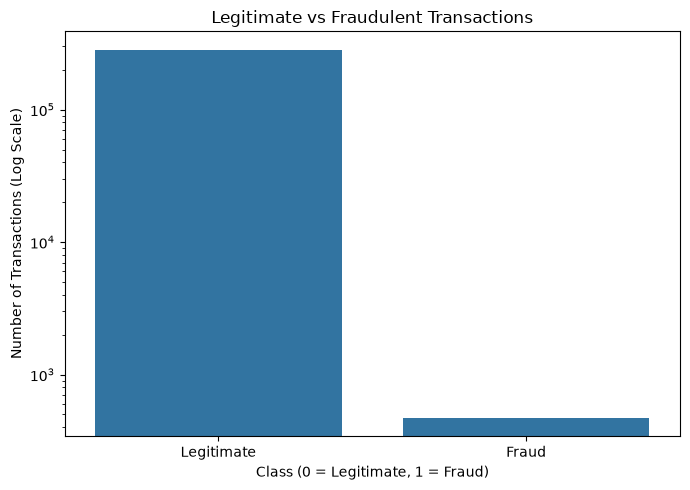

In [30]:
#imbalance between legitimate and fraudulent transactions
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Class")

plt.yscale("log")
plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions (Log Scale)")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.tight_layout()
plt.show()

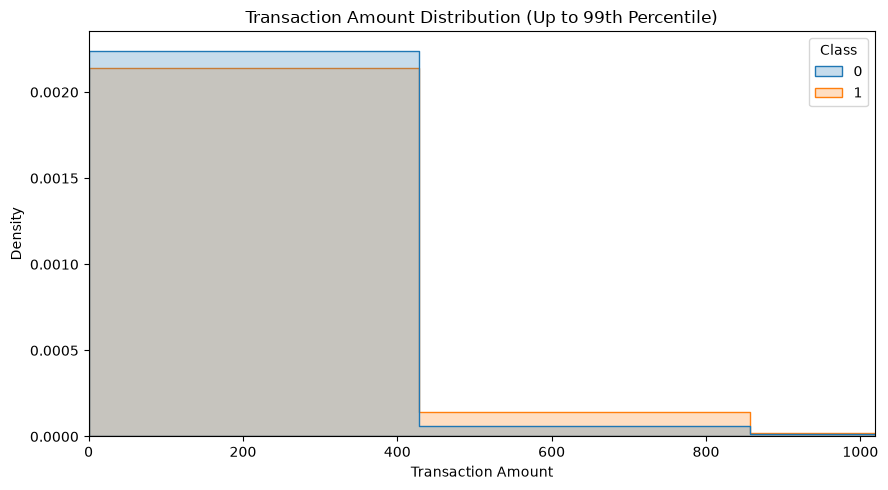

In [31]:
#how transaction amounts are distributed and compares fraud with legitimate transactions
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=60,
    stat="density",
    common_norm=False,
    element="step"
)

plt.xlim(0, df["Amount"].quantile(0.99))
plt.title("Transaction Amount Distribution (Up to 99th Percentile)")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

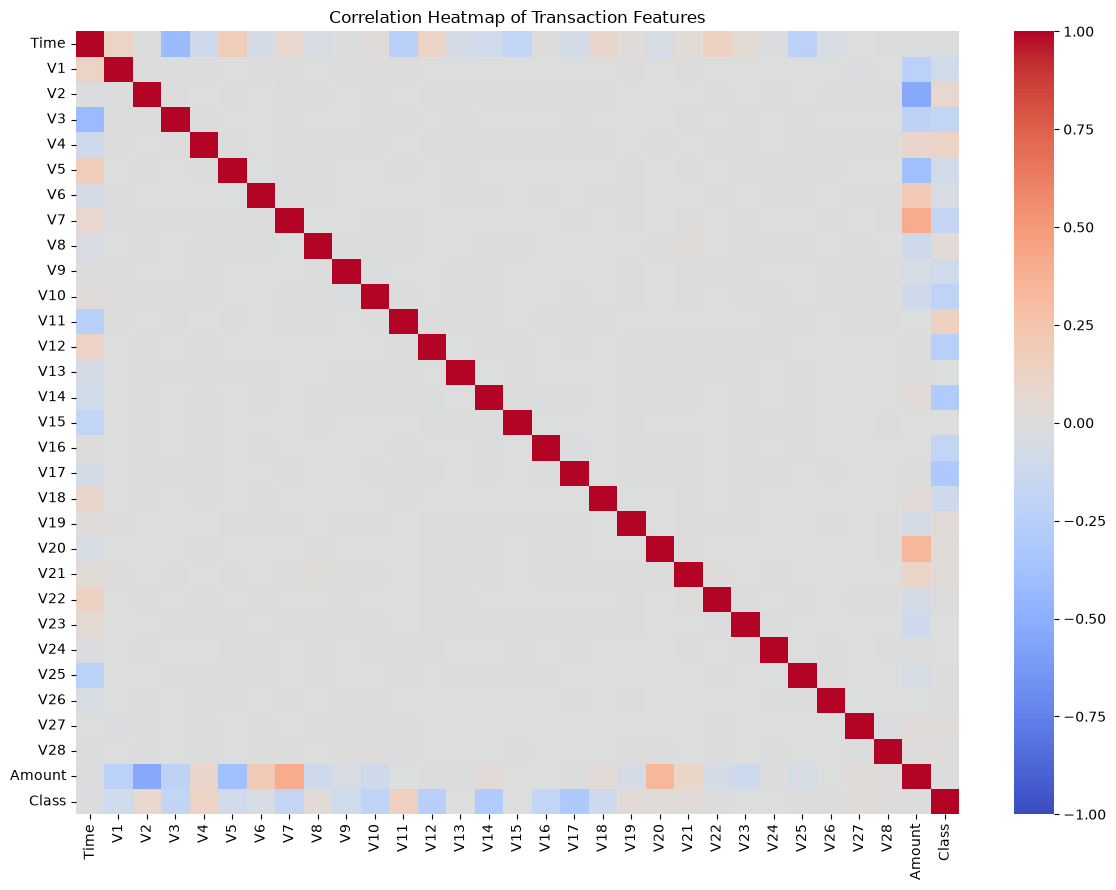

In [34]:
#relationships between numerical features and helps explain which features may be associated with fraud.
plt.figure(figsize=(12, 9))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Transaction Features")
plt.tight_layout()
plt.show()

In [15]:
#train-test
X = df.drop("Class", axis=1)
y = df["Class"]

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Fraud cases in training:", (y_train == 1).sum())
print("Fraud cases in testing:", (y_test == 1).sum())

Fraud cases in training: 378
Fraud cases in testing: 95


In [19]:
#scaling the data
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[["Amount", "Time"]] = scaler.fit_transform(
    X_train[["Amount", "Time"]]
)

X_test_scaled[["Amount", "Time"]] = scaler.transform(
    X_test[["Amount", "Time"]]
)
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)
print("\nScaled training data:")
display(X_train_scaled.head())

Training data shape: (226980, 30)
Testing data shape: (56746, 30)

Scaled training data:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
226238,1.045499,2.238954,-1.724499,-2.151484,-2.577803,0.993668,3.565492,-1.785957,0.860122,-1.264003,...,-0.323810,-0.149574,-0.049333,0.278442,0.684735,-0.219028,-0.159167,0.037920,-0.049932,-0.229434
134253,-0.298690,-1.315062,1.630783,0.597001,-0.038359,-0.404580,-0.965712,0.212249,0.735381,-1.267926,...,-0.067580,-0.238898,-0.946773,0.323904,0.515632,-0.713000,-0.266503,-0.017794,0.051058,-0.331197
186465,0.678397,1.908801,0.021184,-2.087997,0.129310,1.161468,0.605244,-0.022371,0.180296,0.283819,...,-0.210474,0.293609,1.095842,-0.044874,-1.689517,0.106098,0.007758,0.045164,-0.053068,-0.298809
149493,-0.074929,1.811257,0.316556,0.316751,3.880231,0.048454,1.020163,-0.734868,0.233651,0.681423,...,-0.228032,0.138869,0.700422,0.174064,0.702997,-0.212523,-0.010018,-0.017740,-0.038006,-0.289247
18461,-1.376728,1.358817,-1.120881,0.550266,-1.547659,-1.194950,0.275448,-1.201843,0.212889,-2.094285,...,-0.361686,-0.340972,-0.636442,0.252758,-0.344160,-0.064282,-0.439622,0.062524,0.013095,-0.261985


In [20]:
print("Amount mean:", round(X_train_scaled["Amount"].mean(), 3))
print("Amount standard deviation:", round(X_train_scaled["Amount"].std(), 3))

print("\nTime mean:", round(X_train_scaled["Time"].mean(), 3))
print("Time standard deviation:", round(X_train_scaled["Time"].std(), 3))

Amount mean: 0.0
Amount standard deviation: 1.0

Time mean: -0.0
Time standard deviation: 1.0


In [21]:
#Model1- Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)
lr_model.fit(X_train_scaled, y_train)
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [22]:
y_pred_lr = lr_model.predict(X_test_scaled)

print("Predictions completed!")
print("First 20 predictions:", y_pred_lr[:20])

Predictions completed!
First 20 predictions: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [23]:
import pandas as pd

print("Prediction counts:")
print(pd.Series(y_pred_lr).value_counts().sort_index())

print("\nActual test labels:")
print(y_test.value_counts().sort_index())

Prediction counts:
0    55270
1     1476
Name: count, dtype: int64

Actual test labels:
Class
0    56651
1       95
Name: count, dtype: int64


In [24]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)

print(cm)

[[55258  1393]
 [   12    83]]


In [25]:
print(confusion_matrix(y_test, y_pred_lr))

[[55258  1393]
 [   12    83]]


In [26]:
from sklearn.metrics import precision_score, recall_score,f1_score,accuracy_score

precision = precision_score(y_test, y_pred_lr, pos_label=1)
recall = recall_score(y_test, y_pred_lr, pos_label=1)
f1 = f1_score(y_test, y_pred_lr, pos_label=1)
accuracy = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Logistic Regression Results
---------------------------
Accuracy  : 0.9752
Precision : 0.0562
Recall    : 0.8737
F1-Score  : 0.1057


In [27]:
#Model 2- Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_scaled, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [28]:
y_pred_rf = rf_model.predict(X_test_scaled)

print("Random Forest predictions completed!")
print("First 20 predictions:", y_pred_rf[:20])

Random Forest predictions completed!
First 20 predictions: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [29]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,average_precision_score

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)

y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]
pr_auc_rf = average_precision_score(y_test, y_prob_rf)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy  : {accuracy_rf:.4f}")
print(f"Precision : {precision_rf:.4f}")
print(f"Recall    : {recall_rf:.4f}")
print(f"F1-Score  : {f1_rf:.4f}")
print(f"PR-AUC    : {pr_auc_rf:.4f}")

Random Forest Results
---------------------
Accuracy  : 0.9995
Precision : 0.9452
Recall    : 0.7263
F1-Score  : 0.8214
PR-AUC    : 0.8012


In [35]:
# Compare both trained models
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],
    "PR-AUC": [
        average_precision_score(
            y_test, lr_model.predict_proba(X_test_scaled)[:, 1]
        ),
        average_precision_score(
            y_test, rf_model.predict_proba(X_test_scaled)[:, 1]
        )
    ]
})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,PR-AUC
0,Logistic Regression,0.9752,0.0562,0.8737,0.1057,0.6719
1,Random Forest,0.9995,0.9452,0.7263,0.8214,0.8012


In [39]:
import os
import joblib

# Create a folder for saved models
os.makedirs("../models", exist_ok=True)

# Save trained models and scaler
joblib.dump(lr_model, "../models/logistic_regression.pkl")
joblib.dump(rf_model, "../models/random_forest.pkl")
joblib.dump(scaler, "../models/scaler.pkl")

# Save the feature names in the correct order
joblib.dump(list(X_train_scaled.columns), "../models/feature_columns.pkl")

print("Models and scaler saved successfully!")


Models and scaler saved successfully!


In [41]:
# pip install streamlit joblib